# Brent Oil Price Forecasting: 10-Trading-Day Horizon
### QF5210 Financial Time Series

This study compares statistical and machine-learning models for forecasting Brent spot prices 10 trading days ahead. Models are selected using walk-forward validation and evaluated on a separate October 2026 holdout. Forecast accuracy, directional performance, economic value and prediction uncertainty are assessed against a random-walk benchmark.

The analysis uses FRED/EIA and Yahoo Finance observations through **27 October 2026**. There are **676 common validation forecasts** for each of 23 candidates and **17 October holdout targets**. The final forecast is made from the **30 September 2026** origin.

## 1. Evaluation Design

| Stage | Period | Purpose |
|---|---|---|
| Initial estimation history | Before January 2024 | Diagnostics and initial rolling estimation windows |
| Validation | Origins from 1 January 2024; targets through 16 September 2026 | Model and hyperparameter selection by MAPE |
| Holdout | Target dates 1–23 October 2026 | Evaluation of the prespecified model shortlist |
| Holdout estimation limit | Earlier of the forecast origin and 30 September 2026 | Exclude future observations and October outcomes from fitting |
| Final forecast | Origin 30 September 2026 | Predict the price 10 observed Brent trading days ahead |

Early-October targets have September forecast origins. The first holdout forecast originates on **17 September**, so validation targets end on **16 September**. This ensures that model selection uses only information available before any holdout forecast is made. The selected specification remains fixed throughout holdout evaluation.

Estimation uses rolling windows of approximately 3,000 observations. The analysis is **pseudo-out-of-sample**: historical data are dated by observation, rather than archived publication timestamps. Publication lags and subsequent revisions limit conclusions about real-time implementation.

In [1]:
from pathlib import Path
import sys, os, json, time, warnings, hashlib, inspect, importlib.metadata
from functools import partial
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.multitest import multipletests
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from arch import arch_model
from threadpoolctl import threadpool_limits

# Works when launched from the repository root or its notebooks/ directory.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src' / 'models.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Place this notebook in the shared repository notebooks/ folder.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data import load_brent_spot, load_sp500, load_exogenous
from src.features import log_returns, realised_volatility, make_lag_features
from src.models import (random_walk_forecast, historical_mean_forecast,
                        ar1_forecast, var_forecast, xgb_forecast,
                        direct_forecast, direct_lags_forecast, spread_mr_forecast)
from src.backtest import walk_forward
from src.metrics import compare_models, accuracy_metrics

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 180)
# Avoid allocating every CPU to each small regression.
_thread_limit = threadpool_limits(limits=1)
SEED = 5210
H, LOOKBACK = 10, 3000
DATA_START = '1987-01-01'
DATA_END = '2026-10-30'       # fixed observation-date snapshot; change deliberately for an update
VAL_START = pd.Timestamp('2024-01-01')
FIT_CUTOFF = pd.Timestamp('2026-09-30')
TEST_START, TEST_END = pd.Timestamp('2026-10-01'), pd.Timestamp('2026-10-23')
FINAL_ORIGIN = FIT_CUTOFF
USE_EXOG = True             # False permits a Brent-only CSV; VAR/spread candidates are then omitted
REFRESH_DATA = False        # True downloads and replaces the local cache; save old snapshots first
INPUT_CSV = ROOT / 'data' / 'h10_inputs.csv'
OUT = ROOT / 'data' / 'h10_outputs'
OUT.mkdir(parents=True, exist_ok=True)
TIE_PP = 0.002              # MAPE percentage POINTS, not a 0.2% relative improvement
MIN_ECON_TRADES = 20        # suppress unstable annualised metrics in very short test windows
print('Repository:', ROOT)
print('Horizon:', H, 'observed Brent days; fitting window:', LOOKBACK)

Repository: /workspace/Sample-Taxed
Horizon: 10 observed Brent days; fitting window: 3000


### Data Sources

| Variable | Source | Definition |
|---|---|---|
| Brent spot | FRED/EIA `DCOILBRENTEU` | Brent spot price, USD/barrel |
| WTI spot | FRED/EIA `DCOILWTICO` | WTI spot price, USD/barrel |
| S&P 500 | Yahoo Finance `^GSPC` | Equity market index |
| Broad USD index | FRED `DTWEXBGS` | Trade-weighted US dollar index |
| VIX | FRED `VIXCLS` | Equity implied-volatility index |
| OVX | FRED `OVXCLS` | Oil implied-volatility index |

The raw Brent sample spans **20 May 1987–27 October 2026**. After initial feature availability and warm-up requirements, the common modelling sample spans **11 May 2007–27 October 2026**.

All models use the same archived data snapshot, stored in `data/h10_inputs.csv`. Source downloads are used when a local snapshot is unavailable. The snapshot hash and package versions are recorded with the results for reproducibility.

In [2]:
def check_raw(frame):
    frame = frame.copy()
    frame.index = pd.to_datetime(frame.index, errors='raise')
    if frame.index.tz is not None:
        frame.index = frame.index.tz_localize(None)
    frame.index = frame.index.normalize()
    if frame.index.has_duplicates:
        raise ValueError('Duplicate observation dates in input CSV. Resolve them before modelling.')
    frame = frame.sort_index().loc[DATA_START:DATA_END]
    required = ['brent_spot'] + (['wti', 'sp500', 'usd', 'vix', 'ovx'] if USE_EXOG else [])
    missing = set(required) - set(frame.columns)
    if missing:
        raise ValueError(f'Missing raw-level columns: {sorted(missing)}. Use USE_EXOG=False for Brent-only analysis.')
    frame = frame[required].apply(pd.to_numeric, errors='raise')
    frame = frame.replace([np.inf, -np.inf], np.nan)
    # Actual Brent observations define the calendar: never forward-fill the target price.
    frame = frame.loc[frame.brent_spot.notna()]
    if frame.empty or (frame.brent_spot <= 0).any():
        raise ValueError('Brent prices must be observed, positive, and nonempty.')
    if frame.index.min() > VAL_START or len(frame.loc[:VAL_START]) < LOOKBACK + 100:
        raise ValueError('Insufficient pre-2024 history for a 3,000-observation training window.')
    return frame

if INPUT_CSV.exists() and not REFRESH_DATA:
    raw = pd.read_csv(INPUT_CSV, index_col=0, parse_dates=True)
    input_source = f'Local CSV: {INPUT_CSV.name}'
else:
    try:
        brent = load_brent_spot(start=DATA_START, end=DATA_END)
        if USE_EXOG:
            # Retain each source calendar until joining; never backfill from a future date.
            exog = load_exogenous(start=DATA_START, end=DATA_END)
            equities = load_sp500(start=DATA_START, end=DATA_END)
            if equities.empty:
                raise ValueError('Yahoo returned no S&P 500 observations.')
            raw = brent.join([exog, equities], how='outer').ffill(limit=5)
            # Restore target observations: a filled Brent value must not create a trading day.
            raw = raw.reindex(brent.index)
            raw['brent_spot'] = brent['brent_spot']
        else:
            raw = brent
        input_source = 'Shared FRED/EIA and Yahoo source loaders' if USE_EXOG else 'Shared FRED/EIA Brent loader'
    except Exception as exc:
        raise RuntimeError(
            'Real data could not be downloaded. Enable fred.stlouisfed.org and Yahoo finance '
            'data domains in environment settings, or supply data/h10_inputs.csv. '
            'No example or synthetic data will be used as Brent results. '
            f'Original error: {type(exc).__name__}: {exc}'
        ) from exc
raw = check_raw(raw)
if not INPUT_CSV.exists() or REFRESH_DATA:
    INPUT_CSV.parent.mkdir(parents=True, exist_ok=True)
    raw.to_csv(INPUT_CSV, index_label='date')
DATA_HASH = hashlib.sha256(INPUT_CSV.read_bytes()).hexdigest()
print(input_source)
print(f'Raw Brent calendar: {raw.index[0].date()} to {raw.index[-1].date()}, {len(raw):,} observations')
print('Input CSV SHA256:', DATA_HASH)
display(raw.tail())

Shared FRED/EIA and Yahoo source loaders
Raw Brent calendar: 1987-05-20 to 2026-10-27, 9,117 observations
Input CSV SHA256: 3b7db8429322f52603d60f8af79c3c4b018d62b9747d23559ce5c00175065ead


/workspace/.venvs/schoolwork/lib/python3.12/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/workspace/.venvs/schoolwork/lib/python3.12/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/workspace/.venvs/schoolwork/lib/python3.12/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={
/workspace/.venvs/schoolwork/lib/p

,brent_spot,wti,sp500,usd,vix,ovx
DATE,,,,,,
2026-10-21,117.37,103.95,7757.169922,121.3422,16.68,53.28
2026-10-22,125.39,104.27,7663.430176,121.3531,19.03,55.64
2026-10-23,128.30,109.72,7623.680176,121.3202,19.45,60.02
2026-10-26,128.12,105.25,7676.770020,121.3202,18.39,58.71
2026-10-27,123.10,103.37,7722.600098,121.3202,17.52,55.44


## 2. Data Preparation and Features

Brent prices are transformed into daily log returns. The forecasting target is the cumulative 10-day log return,

\[
y_{t,10}=\log(P_{t+10}/P_t), \qquad
\widehat P_{t+10}=P_t\exp(\widehat y_{t,10}).
\]

S&P 500 and USD inputs use log returns; VIX and OVX use log levels. WTI uses changes in `asinh(WTI/50)`, which remain defined during the negative WTI price observation in April 2020. The spread model uses the relative Brent–WTI price spread.

External daily observations are lagged by one Brent observation, and USD by five, as conservative availability assumptions. Brent observation dates define the trading-day calendar. Only initial incomplete rows are trimmed; internal missing predictors do not cause trading dates to be deleted, and target prices are never forward-filled.

The VAR predictor sets are **S1:** Brent, WTI and S&P 500; **S2:** S1 plus USD and VIX; **S3:** S2 plus OVX. EPU and GPR are excluded to limit additional publication-timing assumptions.

In [3]:
df = pd.DataFrame(index=raw.index)
df['brent_spot'] = raw.brent_spot
df['log_return'] = log_returns(raw)
if USE_EXOG:
    known = raw[['wti', 'sp500', 'usd', 'vix', 'ovx']].ffill(limit=5)
    df['wti_spot'] = known.wti.shift(1)
    df['wti'] = np.arcsinh(known.wti / 50).diff().shift(1)
    for c in ['sp500', 'usd']:
        if (known[c].dropna() <= 0).any():
            raise ValueError(f'{c} must be positive for logs.')
        df[c] = np.log(known[c]).diff().shift(5 if c == 'usd' else 1)
    for c in ['vix', 'ovx']:
        if (known[c].dropna() <= 0).any():
            raise ValueError(f'{c} must be positive for logs.')
        df[c] = np.log(known[c]).shift(1)
complete = np.isfinite(df.to_numpy()).all(axis=1)
if not complete.any():
    raise ValueError('No complete initial feature row: check input columns and history.')
first_complete = np.flatnonzero(complete)[0]
df = df.iloc[first_complete:].copy()
if not np.isfinite(df.to_numpy()).all():
    bad = df.index[~np.isfinite(df.to_numpy()).all(axis=1)]
    raise ValueError(f'Internal feature gaps on {list(bad[:5])}; repair source data, do not drop trading dates.')
assert df.index.equals(raw.loc[df.index[0]:].index)
assert (df.brent_spot > 0).all()

# Observation dates, rather than a generic weekday calendar, define all historical targets.
first_target_pos = df.index.searchsorted(TEST_START)
if first_target_pos >= len(df) or df.index[first_target_pos] > TEST_END:
    raise ValueError('No October test observations available. Supply an updated real CSV; no test result can be claimed.')
first_test_origin_pos = first_target_pos - H
if first_test_origin_pos <= LOOKBACK:
    raise ValueError('Insufficient fitting history before the first October forecast origin.')
FIRST_TEST_ORIGIN = df.index[first_test_origin_pos]
SELECTION_END = df.index[first_test_origin_pos - 1]
assert SELECTION_END < FIRST_TEST_ORIGIN <= FIT_CUTOFF
assert (df.index < VAL_START).sum() > LOOKBACK + 100
print(f'Modelling sample: {df.index[0].date()}–{df.index[-1].date()} ({len(df):,} rows)')
print(f'First test target: {df.index[first_target_pos].date()}; its origin: {FIRST_TEST_ORIGIN.date()}')
print(f'Validation targets end: {SELECTION_END.date()}; specification is locked before the first test origin.')
print(f'Available October target observations: {sum((df.index >= TEST_START) & (df.index <= TEST_END))}')
if df.index[-1] < TEST_END:
    print('PARTIAL OCTOBER TEST: rerun after the remaining spot observations are published.')

Modelling sample: 2007-05-11–2026-10-27 (4,921 rows)
First test target: 2026-10-01; its origin: 2026-09-17
Validation targets end: 2026-09-16; specification is locked before the first test origin.
Available October target observations: 17


## 3. Preliminary Diagnostics

Augmented Dickey–Fuller tests assess stationarity, Ljung–Box tests assess return autocorrelation, and ARCH-LM tests assess volatility clustering. All diagnostics use pre-2024 observations.

ACF and PACF plots use non-overlapping 10-day returns to avoid autocorrelation induced mechanically by overlapping return sums. These diagnostics describe the series and motivate candidate models; predictive performance is assessed separately out of sample.

/tmp/ipykernel_590/2914029000.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  a = adfuller(series, maxlag=20, autolag='AIC')
/tmp/ipykernel_590/2914029000.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  a = adfuller(series, maxlag=20, autolag='AIC')
/tmp/ipykernel_590/2914029000.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on 

,ADF statistic,ADF p,n
series,,,
log price,-2.86175,0.04998,4191
daily log return,-15.00155,0.00000,4192
non-overlapping 10-day return,-17.55101,0.00000,419


,lb_stat,lb_pvalue
10,52.510194,9.179242e-08
20,122.750792,8.804279e-17


/workspace/.venvs/schoolwork/lib/python3.12/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


ARCH-LM(10): statistic=733.885, p=3.3256e-151


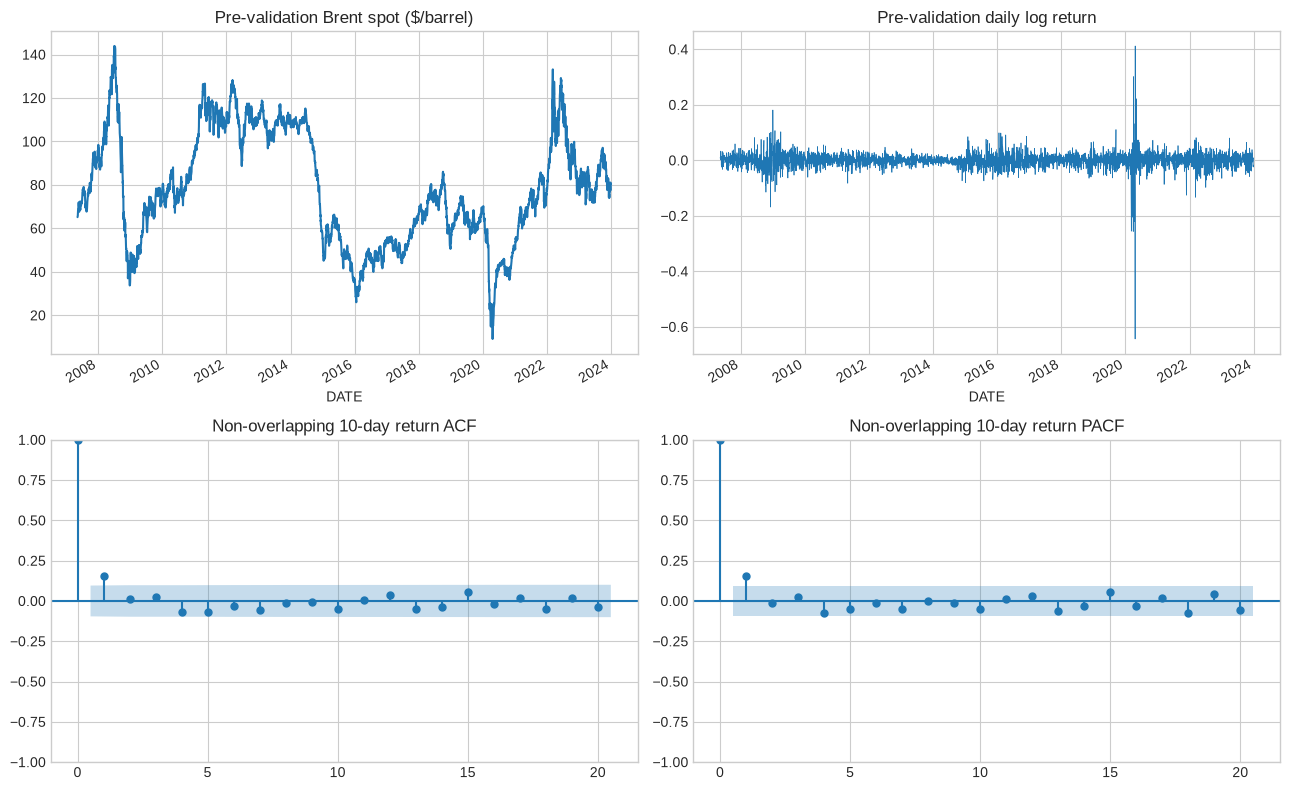

In [4]:
pre = df.loc[df.index < VAL_START]
r = pre.log_return
nonoverlap = r.rolling(H).sum().iloc[H-1::H].dropna()
diagnostic_rows = []
for label, series in [('log price', np.log(pre.brent_spot)), ('daily log return', r),
                      ('non-overlapping 10-day return', nonoverlap)]:
    a = adfuller(series, maxlag=20, autolag='AIC')
    diagnostic_rows.append({'series': label, 'ADF statistic': a[0], 'ADF p': a[1], 'n': a[3]})
diagnostics = pd.DataFrame(diagnostic_rows).set_index('series')
display(diagnostics.round(5))
display(acorr_ljungbox(r, lags=[10, 20], return_df=True))
arch_stat, arch_p, _, _ = het_arch(r * 100, nlags=10)
print(f'ARCH-LM(10): statistic={arch_stat:.3f}, p={arch_p:.5g}')
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
pre.brent_spot.plot(ax=axes[0, 0], title='Pre-validation Brent spot ($/barrel)')
r.plot(ax=axes[0, 1], title='Pre-validation daily log return', linewidth=0.5)
sm.graphics.tsa.plot_acf(nonoverlap, lags=20, ax=axes[1, 0])
sm.graphics.tsa.plot_pacf(nonoverlap, lags=20, ax=axes[1, 1], method='ywm')
axes[1, 0].set_title('Non-overlapping 10-day return ACF')
axes[1, 1].set_title('Non-overlapping 10-day return PACF')
plt.tight_layout(); plt.show()

## 4. Forecasting Models

| Family | Specifications | Forecasting approach |
|---|---|---|
| Benchmarks | Random walk, historical mean, AR(1) | No change, average drift and short-run persistence |
| ARIMA | (0,1,1), (1,1,1) on log prices | Iterated forecasts from ARMA models of daily log returns |
| Direct OLS | Trailing 10-day return; short/long windows (1,20), (5,60) | Direct regression of future 10-day returns on past returns |
| VAR | S1, S2 and S3; lag orders 1 and 3 | Joint daily forecasts aggregated to the Brent horizon |
| Spread mean reversion | Relative Brent–WTI spread | Direct return forecast from the observed spread |
| Ridge | Penalties 10 and 100 | Regularised regression using momentum, volatility and external inputs |
| XGBoost | 50 or 150 trees; depth 1 or 2 | Shallow nonlinear direct-return models |
| GARCH | Constant-mean GARCH(1,1), Student-t errors | Drift-based point forecast with time-varying volatility |
| Combination | Equal weights on RW, direct OLS and AR(1) | Averaging in log-return space |

The 23 candidates are specified before validation scoring. For each direct-model training pair, the target date must be no later than the fitting date. Iterated models forecast daily dynamics and aggregate them over the 10-day horizon.

GARCH primarily models uncertainty. A constant-mean version is included in the point-forecast comparison, while zero-mean GARCH supplies prediction intervals around the selected forecast. Model-fitting failures are reported rather than replaced by benchmark forecasts.

In [5]:
def arima_forecast(frame, origin_idx, horizon, fit_idx, lookback=LOOKBACK, order=(0, 1)):
    """ARMA(p,q) on daily log returns = ARIMA(p,1,q) on log prices."""
    if fit_idx > origin_idx or fit_idx - lookback + 1 < 0:
        raise ValueError('Invalid ARIMA fitting window.')
    window = frame.log_return.iloc[fit_idx-lookback+1:fit_idx+1].to_numpy() * 100
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ConvergenceWarning)
        fitted = ARIMA(window, order=(order[0], 0, order[1]), trend='c').fit(
            method_kwargs={'maxiter': 300})
    if not fitted.mle_retvals.get('converged', True):
        raise RuntimeError('ARIMA optimisation did not converge.')
    if origin_idx > fit_idx:
        # Update the state with observed returns; parameters stay frozen.
        fitted = fitted.append(frame.log_return.iloc[fit_idx+1:origin_idx+1].to_numpy() * 100, refit=False)
    pred = float(np.sum(fitted.forecast(steps=horizon))) / 100
    return float(frame.brent_spot.iloc[origin_idx] * np.exp(pred))

def garch_fit(frame, origin_idx, fit_idx, lookback=LOOKBACK, mean='Constant'):
    start = fit_idx - lookback + 1
    if not (0 <= start <= fit_idx <= origin_idx):
        raise ValueError('Invalid GARCH fitting window.')
    spec = dict(mean=mean, vol='GARCH', p=1, q=1, dist='t', rescale=False)
    fit = arch_model(frame.log_return.iloc[start:fit_idx+1].to_numpy()*100, **spec).fit(
        disp='off', show_warning=False, options={'maxiter': 1000})
    if fit.convergence_flag != 0:
        raise RuntimeError(f'GARCH failed to converge: {fit.optimization_result.message}')
    if origin_idx > fit_idx:
        fit = arch_model(frame.log_return.iloc[start:origin_idx+1].to_numpy()*100, **spec).fix(fit.params)
    return fit

def garch_mean_forecast(frame, origin_idx, horizon, fit_idx, lookback=LOOKBACK):
    fit = garch_fit(frame, origin_idx, fit_idx, lookback, mean='Constant')
    mu = float(fit.params['mu']) / 100
    return float(frame.brent_spot.iloc[origin_idx] * np.exp(horizon * mu))

# Model inputs are backward looking. Future labels are built separately inside each fit.
def ridge_features(frame):
    F = make_lag_features(frame, ['log_return'], lags=3)
    for w in [5, 10, 20, 60]:
        F[f'momentum_{w}'] = frame.log_return.rolling(w).sum()
    F['vol_20'] = realised_volatility(frame, window=20)
    F['vol_60'] = realised_volatility(frame, window=60)
    if USE_EXOG:
        for c in ['wti', 'sp500', 'usd', 'vix', 'ovx']:
            F[c] = frame[c]  # already shifted in preprocessing
        F['spread'] = (frame.brent_spot - frame.wti_spot) / frame.brent_spot
    return F

RIDGE_FEATURES = ridge_features(df)
XGB_FEATURES = RIDGE_FEATURES.copy()

def ridge_forecast(frame, origin_idx, horizon, fit_idx, lookback=LOOKBACK, alpha=100):
    if not 0 <= fit_idx-lookback+1 <= fit_idx <= origin_idx:
        raise ValueError('Invalid ridge fitting window.')
    positions = np.arange(fit_idx-lookback+1, fit_idx-horizon+1)
    X = RIDGE_FEATURES.iloc[positions]
    y = np.log(frame.brent_spot.iloc[positions+horizon].to_numpy() /
               frame.brent_spot.iloc[positions].to_numpy())
    keep = np.isfinite(X.to_numpy()).all(axis=1) & np.isfinite(y)
    assert positions.max() + horizon <= fit_idx
    pipe = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    pipe.fit(X.loc[keep], y[keep])
    pred = float(pipe.predict(RIDGE_FEATURES.iloc[[origin_idx]])[0])
    return float(frame.brent_spot.iloc[origin_idx] * np.exp(pred))

def combination_forecast(frame, origin_idx, horizon, fit_idx):
    members = [random_walk_forecast,
               partial(direct_forecast, lookback=LOOKBACK),
               partial(ar1_forecast, lookback=LOOKBACK)]
    p0 = frame.brent_spot.iloc[origin_idx]
    ret = [np.log(fn(frame, origin_idx, horizon, fit_idx)/p0) for fn in members]
    return float(p0 * np.exp(np.mean(ret)))

MODELS, SPECS = {}, {}
def register(name, fn, family, complexity, **kwargs):
    MODELS[name] = partial(fn, **kwargs)
    SPECS[name] = {'family': family, 'complexity': complexity,
                   'function': fn.__name__, 'parameters': {k: str(v) for k, v in kwargs.items()}}

register('Random Walk', random_walk_forecast, 'Benchmark', 0)
register('Historical Mean', historical_mean_forecast, 'Benchmark', 1, lookback=LOOKBACK)
register('AR(1)', ar1_forecast, 'Benchmark', 2, lookback=LOOKBACK)
for pq in [(0, 1), (1, 1)]:
    register(f'ARIMA({pq[0]},1,{pq[1]})', arima_forecast, 'ARIMA', 3+sum(pq), order=pq)
register('Direct OLS (10d)', direct_forecast, 'Direct', 3, lookback=LOOKBACK)
for short, long in [(1, 20), (5, 60)]:
    register(f'Direct lags ({short},{long})', direct_lags_forecast, 'Direct', 4,
             lookback=LOOKBACK, short=short, long=long, nonoverlap=True)
if USE_EXOG:
    stages = {'S1': ['log_return', 'wti', 'sp500'],
              'S2': ['log_return', 'wti', 'sp500', 'usd', 'vix'],
              'S3': ['log_return', 'wti', 'sp500', 'usd', 'vix', 'ovx']}
    for stage, cols in stages.items():
        for p in [1, 3]:
            register(f'VAR {stage} p={p}', var_forecast, 'VAR', 10+len(cols)*p,
                     cols=cols, lags=p, lookback=LOOKBACK)
    register('Spread mean reversion', spread_mr_forecast, 'Spread', 4, lookback=LOOKBACK)
for alpha in [10, 100]:
    register(f'Ridge alpha={alpha}', ridge_forecast, 'Ridge', 20, alpha=alpha)
for n in [50, 150]:
    for depth in [1, 2]:
        # Large input DataFrame is bound separately, not serialised into the spec table.
        name = f'XGB n={n} depth={depth}'
        register(name, xgb_forecast, 'XGBoost', 30+depth*2+n/1000,
                 lookback=LOOKBACK, n_estimators=n, max_depth=depth,
                 min_child_weight=20, learning_rate=0.03)
        MODELS[name] = partial(MODELS[name], features=XGB_FEATURES)
register('GARCH(1,1)-t mean', garch_mean_forecast, 'GARCH', 6)
register('Fixed combination', combination_forecast, 'Combination', 8)
display(pd.DataFrame(SPECS).T[['family', 'function', 'parameters']])
print(len(MODELS), 'candidates, declared before scoring. Complexity is an explicit tie-break ranking, not parameter count.')

,family,function,parameters
Random Walk,Benchmark,random_walk_forecast,{}
Historical Mean,Benchmark,historical_mean_forecast,{'lookback': '3000'}
AR(1),Benchmark,ar1_forecast,{'lookback': '3000'}
"ARIMA(0,1,1)",ARIMA,arima_forecast,"{'order': '(0, 1)'}"
"ARIMA(1,1,1)",ARIMA,arima_forecast,"{'order': '(1, 1)'}"
Direct OLS (10d),Direct,direct_forecast,{'lookback': '3000'}
"Direct lags (1,20)",Direct,direct_lags_forecast,"{'lookback': '3000', 'short': '1', 'long': '20..."
"Direct lags (5,60)",Direct,direct_lags_forecast,"{'lookback': '3000', 'short': '5', 'long': '60..."
VAR S1 p=1,VAR,var_forecast,"{'cols': '['log_return', 'wti', 'sp500']', 'la..."
VAR S1 p=3,VAR,var_forecast,"{'cols': '['log_return', 'wti', 'sp500']', 'la..."


23 candidates, declared before scoring. Complexity is an explicit tie-break ranking, not parameter count.


### Walk-Forward Backtesting

Each forecast is generated using information available at its origin. Target-date evaluation windows are converted into the corresponding origin dates, including September origins for early-October targets.

All models are evaluated on identical origin–target pairs, with each target exactly 10 observed Brent trading days after its origin. No shuffled train/test split or random cross-validation is used.

In [6]:
def checked_model(fn, model_name):
    def forecast(frame, origin_idx, horizon, fit_idx):
        assert fit_idx <= origin_idx
        assert fit_idx >= LOOKBACK - 1
        try:
            result = float(fn(frame, origin_idx, horizon, fit_idx))
            if not np.isfinite(result) or result <= 0:
                raise ValueError(f'Invalid price forecast {result}')
            return result
        except Exception as exc:
            raise RuntimeError(f'{model_name}: origin {frame.index[origin_idx].date()}, '
                               f'fit through {frame.index[fit_idx].date()}: {exc}') from exc
    return forecast

def run_target_window(fn, name, target_start, target_end, origin_min=None, fit_cutoff=None):
    dates = df.index
    js = np.arange(len(dates))
    eligible = (dates >= pd.Timestamp(target_start)) & (dates <= pd.Timestamp(target_end)) & (js >= H)
    targets = js[eligible]
    if origin_min is not None:
        targets = targets[dates[targets-H] >= pd.Timestamp(origin_min)]
    if len(targets) == 0:
        raise ValueError(f'{name}: no available targets for this window.')
    origins = targets - H
    end = dates[origins[-1]] + pd.Timedelta(days=1)  # shared end_date is exclusive
    res = walk_forward(df, horizon=H, start_date=dates[origins[0]], end_date=end,
                       forecast_funct=checked_model(fn, name),
                       fit_end_date=fit_cutoff, target_end_date=pd.Timestamp(target_end))
    res = res.loc[res.target_date.between(pd.Timestamp(target_start), pd.Timestamp(target_end))].reset_index(drop=True)
    assert len(res) == len(targets)
    assert pd.DatetimeIndex(res.origin_date).equals(dates[origins])
    assert pd.DatetimeIndex(res.target_date).equals(dates[targets])
    assert (res.actual.to_numpy() == df.brent_spot.iloc[targets].to_numpy()).all()
    return res

def assert_common(results):
    keys = ['origin_date', 'target_date']
    first = next(iter(results.values()))
    for name, res in results.items():
        assert not res.duplicated(keys).any(), name
        assert res[keys].equals(first[keys]), f'Different evaluation dates: {name}'
        np.testing.assert_allclose(res.actual, first.actual)
        np.testing.assert_allclose(res.origin_price, first.origin_price)
    return len(first)

# Check the direct-label boundary and causality at a representative PRE-validation origin.
probe = np.flatnonzero(df.index < VAL_START)[-1]
positions = np.arange(probe-LOOKBACK+1, probe-H+1)
assert positions[-1] + H == probe
np.testing.assert_allclose(
    df.log_return.rolling(H).sum().shift(-H).iloc[positions],
    np.log(df.brent_spot.iloc[positions+H].to_numpy()/df.brent_spot.iloc[positions].to_numpy()),
    atol=1e-12)
# Future-price perturbation must not alter any already-known features.
altered = df.copy()
altered.loc[altered.index > df.index[probe], ['brent_spot', 'log_return']] *= 1.5
pd.testing.assert_frame_equal(ridge_features(df).iloc[:probe+1], ridge_features(altered).iloc[:probe+1])
print('Training-label boundary, causal feature construction, and observed-calendar checks passed.')

Training-label boundary, causal feature construction, and observed-calendar checks passed.


## 5. Validation and Model Selection

Each candidate is re-estimated at successive origins using the available rolling history. Validation origins begin in January 2024, and all scored targets fall on or before **16 September 2026**.

The primary selection criterion is **MAPE**. Candidates within **0.002 MAPE percentage points** of the minimum are treated as near ties, with preference given to the prespecified simpler specification. The selected model and family representatives are fixed before October evaluation.

In [7]:
validation_results = {}
for name, fn in MODELS.items():
    started = time.perf_counter()
    validation_results[name] = run_target_window(
        fn, name, VAL_START, SELECTION_END, origin_min=VAL_START)
    print(f'{name:28s} {len(validation_results[name]):4d} forecasts, '
          f'{time.perf_counter()-started:6.1f}s', flush=True)
N_VAL = assert_common(validation_results)
assert all(r.target_date.max() < FIRST_TEST_ORIGIN for r in validation_results.values())
print('Validation forecast pairs per model:', N_VAL)

Random Walk                   676 forecasts,    0.0s


Historical Mean               676 forecasts,    0.1s


AR(1)                         676 forecasts,    0.8s


ARIMA(0,1,1)                  676 forecasts,   39.7s


ARIMA(1,1,1)                  676 forecasts,  104.4s


...

XGB n=150 depth=1             676 forecasts,   19.3s


XGB n=150 depth=2             676 forecasts,   28.6s


GARCH(1,1)-t mean             676 forecasts,   11.6s


Fixed combination             676 forecasts,    1.4s


Validation forecast pairs per model: 676


### Evaluation Metrics

**MAE** and **RMSE** measure price errors in USD/barrel. **MAPE** measures percentage error. Lower values indicate greater accuracy. Relative improvements over random walk are positive when a candidate has lower loss.

Directional accuracy, precision, recall and F1 are reported as fractions. Random walk predicts no price change, so its up/down classification metrics are not applicable. Economic performance is evaluated separately using non-overlapping holding periods.

In [8]:
DIRECTION_COLS = ['directional_accuracy', 'precision_up', 'recall_up', 'f1_up',
                  'precision_down', 'recall_down', 'f1_down']

def comparison_table(results):
    assert_common(results)
    table = compare_models(results, horizon=H)
    for name, res in results.items():
        if np.allclose(res.forecast, res.origin_price, atol=1e-10, rtol=0):
            table.loc[name, DIRECTION_COLS] = np.nan
    for metric in ['MAE', 'RMSE', 'MAPE']:
        table[f'{metric}_vs_RW_%'] = 100*(1-table[metric]/table.loc['Random Walk', metric])
    # Replaced below: shared economics are a rough h-spaced approximation.
    return table

val_table = comparison_table(validation_results)
val_table['complexity'] = [SPECS[n]['complexity'] for n in val_table.index]
val_table['family'] = [SPECS[n]['family'] for n in val_table.index]
best_mape = val_table.MAPE.min()
near_ties = val_table.loc[val_table.MAPE <= best_mape + TIE_PP]
WINNER = near_ties.sort_values(['complexity', 'MAPE'], kind='stable').index[0]
FAMILY_WINNERS = []
for family in dict.fromkeys(v['family'] for v in SPECS.values()):
    group = val_table.loc[val_table.family == family]
    tied = group.loc[group.MAPE <= group.MAPE.min()+TIE_PP]
    FAMILY_WINNERS.append(tied.sort_values(['complexity', 'MAPE'], kind='stable').index[0])
# All benchmarks plus the validation-selected representative of each family; fixed before test.
SHORTLIST = list(dict.fromkeys(['Random Walk', 'Historical Mean', 'AR(1)', *FAMILY_WINNERS, WINNER]))
locked_winner = WINNER
selection_record = {
    'winner': WINNER, 'horizon_observations': H, 'lookback': LOOKBACK,
    'validation_origin_start': str(VAL_START.date()),
    'validation_target_end': str(SELECTION_END.date()),
    'first_test_origin': str(FIRST_TEST_ORIGIN.date()),
    'fit_cutoff': str(FIT_CUTOFF.date()), 'test_targets': [str(TEST_START.date()), str(TEST_END.date())],
    'tie_rule_MAPE_percentage_points': TIE_PP, 'input_sha256': DATA_HASH,
    'shortlist': SHORTLIST, 'candidate_specs': SPECS,
}
(OUT/'selection_lock.json').write_text(json.dumps(selection_record, indent=2))
display(val_table[['MAE', 'RMSE', 'MAPE', 'MAPE_vs_RW_%', 'directional_accuracy', 'family']]
        .sort_values('MAPE').round(4))
print('LOCKED MODEL:', WINNER)
print('Best raw validation MAPE:', round(best_mape, 5), '; tie tolerance:', TIE_PP, 'percentage points')
print('This winner will NOT be replaced using October results or a significance-test p-value.')

,MAE,RMSE,MAPE,MAPE_vs_RW_%,directional_accuracy,family
model,,,,,,
"Direct lags (5,60)",4.9467,7.6917,5.8408,0.1452,0.5104,Direct
"ARIMA(1,1,1)",4.9594,7.7286,5.8444,0.0841,0.4882,ARIMA
VAR S1 p=3,4.9618,7.7326,5.8492,0.0020,0.4911,VAR
Random Walk,4.9597,7.7198,5.8493,0.0000,NaN,Benchmark
VAR S1 p=1,4.9643,7.7279,5.8531,-0.0646,0.4852,VAR
"ARIMA(0,1,1)",4.9673,7.7295,5.8562,-0.1171,0.4645,ARIMA
AR(1),4.9676,7.7297,5.8566,-0.1254,0.4704,Benchmark
Historical Mean,4.9698,7.7318,5.8595,-0.1749,0.4719,Benchmark
Fixed combination,4.9649,7.7095,5.8599,-0.1811,0.4778,Combination


LOCKED MODEL: Direct lags (5,60)
Best raw validation MAPE: 5.84081 ; tie tolerance: 0.002 percentage points
This winner will NOT be replaced using October results or a significance-test p-value.


## 6. Economic Performance

The trading proxy takes a long or short position according to the sign of the forecast price change. Positions are initiated every 10 observations and held for 10 observations, avoiding overlapping exposure. Results are also calculated over all ten possible starting offsets.

Transaction costs are **1 basis point per unit of turnover**, including initial entry and final exit. A reversal from long to short incurs two units of turnover. Equity starts at one, and drawdown includes the initial holding period. Returns and volatility are annualised using **252/10 holding periods per year**.

Annualised return, Sharpe and drawdown summaries are suppressed when fewer than 20 non-overlapping holding periods are available. October alone is therefore insufficient for reliable annualised performance estimates. These are stylised spot-return proxies and exclude futures rolls, financing, margin and slippage. Model selection remains based on MAPE.

In [9]:
def economic_metrics(res, offset=0, cost=0.0001):
    trades = res.iloc[offset::H].copy().reset_index(drop=True)
    n = len(trades)
    out = {'n_holding_periods': n, 'turnover': 0.0,
           'annualized_return': np.nan, 'sharpe_ratio': np.nan, 'max_drawdown': np.nan}
    if n == 0:
        return out, pd.DataFrame()
    op = df.index.get_indexer(pd.DatetimeIndex(trades.origin_date))
    tp = df.index.get_indexer(pd.DatetimeIndex(trades.target_date))
    assert ((tp-op) == H).all()
    assert (op[1:] >= tp[:-1]).all(), 'Trading positions overlap.'
    position = np.sign(trades.forecast.to_numpy()-trades.origin_price.to_numpy())
    turnover = np.abs(np.diff(np.r_[0.0, position]))
    turnover[-1] += abs(position[-1])  # liquidate at the final target date
    net = position*(trades.actual.to_numpy()/trades.origin_price.to_numpy()-1)-cost*turnover
    if (net <= -1).any():
        raise ValueError('The unlevered long/short proxy exhausted capital; inspect the strategy.')
    equity = np.r_[1.0, np.cumprod(1+net)]
    drawdown = equity/np.maximum.accumulate(equity)-1
    out['turnover'] = float(turnover.sum())
    if n >= MIN_ECON_TRADES:
        vol = np.std(net, ddof=1)
        out.update(annualized_return=float(np.mean(net)*252/H),
                   sharpe_ratio=float(np.mean(net)/vol*np.sqrt(252/H)) if vol > 0 else np.nan,
                   max_drawdown=float(drawdown.min()))
    curve = pd.DataFrame({'target_date': trades.target_date, 'position': position,
                          'net_return': net, 'equity': equity[1:]})
    return out, curve

for name, res in validation_results.items():
    econ, _ = economic_metrics(res)
    for field in ['annualized_return', 'sharpe_ratio', 'max_drawdown']:
        val_table.loc[name, field] = econ[field]
    val_table.loc[name, 'n_holding_periods'] = econ['n_holding_periods']
    val_table.loc[name, 'num_trades'] = econ['turnover']
economic_sensitivity = []
for name in SHORTLIST:
    values = [economic_metrics(validation_results[name], offset=k)[0]['sharpe_ratio'] for k in range(H)]
    finite = np.asarray(values)[np.isfinite(values)]
    economic_sensitivity.append({'model': name, 'Sharpe offset 0': values[0],
                                 'Sharpe offset median': np.median(finite) if len(finite) else np.nan,
                                 'Sharpe offset min': np.min(finite) if len(finite) else np.nan,
                                 'Sharpe offset max': np.max(finite) if len(finite) else np.nan})
economic_sensitivity = pd.DataFrame(economic_sensitivity).set_index('model')
display(val_table.loc[SHORTLIST, ['MAPE', 'directional_accuracy', 'precision_up', 'recall_up', 'f1_up',
                                'precision_down', 'recall_down', 'f1_down', 'annualized_return',
                                'sharpe_ratio', 'max_drawdown', 'n_holding_periods']].round(4))
display(economic_sensitivity.round(4))

,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,n_holding_periods
model,,,,,,,,,,,,
Random Walk,5.8493,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,NaN,0.0000,68.0
Historical Mean,5.8595,0.4719,0.3571,0.0587,0.1008,0.4823,0.8925,0.6262,-0.3503,-0.7226,-0.8164,68.0
AR(1),5.8566,0.4704,0.3559,0.0616,0.1050,0.4814,0.8866,0.6239,-0.1215,-0.2483,-0.7045,68.0
"ARIMA(1,1,1)",5.8444,0.4882,0.4823,0.1994,0.2822,0.4897,0.7821,0.6023,-0.0971,-0.1985,-0.6827,68.0
"Direct lags (5,60)",5.8408,0.5104,0.5195,0.3900,0.4456,0.5048,0.6328,0.5616,0.4272,0.8860,-0.4193,68.0
VAR S1 p=3,5.8492,0.4911,0.4926,0.2933,0.3676,0.4905,0.6925,0.5743,-0.0566,-0.1156,-0.6407,68.0
Spread mean reversion,5.8627,0.4719,0.4070,0.1026,0.1639,0.4814,0.8478,0.6141,-0.0633,-0.1293,-0.6397,68.0
Ridge alpha=100,6.1835,0.5399,0.5798,0.3196,0.4121,0.5246,0.7642,0.6221,0.1268,0.2592,-0.5530,68.0
XGB n=50 depth=1,5.8764,0.4956,0.0000,0.0000,0.0000,0.4956,1.0000,0.6627,-0.2428,-0.4981,-0.6964,68.0


,Sharpe offset 0,Sharpe offset median,Sharpe offset min,Sharpe offset max
model,,,,
Random Walk,NaN,NaN,NaN,NaN
Historical Mean,-0.7226,-0.5177,-0.9179,-0.2114
AR(1),-0.2483,-0.6683,-1.1195,0.0003
"ARIMA(1,1,1)",-0.1985,-0.3277,-1.5743,0.2182
"Direct lags (5,60)",0.8860,0.2982,-0.4058,0.8860
VAR S1 p=3,-0.1156,-0.2185,-1.4214,0.0786
Spread mean reversion,-0.1293,-0.7153,-1.1754,-0.1293
Ridge alpha=100,0.2592,0.1747,-0.3987,0.8692
XGB n=50 depth=1,-0.4981,-0.5338,-0.6672,-0.4037


## 7. Forecast-Accuracy Significance Tests

Diebold–Mariano tests compare each candidate with random walk under the null of equal expected forecast loss. The primary loss is absolute percentage error; squared error is a secondary specification. A negative statistic favours the candidate.

Bartlett/Newey–West long-run variance accounts for dependent errors, with the Harvey–Leybourne–Newbold small-sample adjustment. Bandwidth 9 addresses mechanical 10-day overlap; bandwidth 20 provides a sensitivity check. Holm adjustment covers all searched candidates within each loss/bandwidth comparison.

These tests are validation diagnostics rather than independent confirmation, because validation also selects the model. Multiplicity adjustment does not eliminate selection bias, nested-model concerns or finite-sample uncertainty. The October sample contains too few independent windows for a reliable 10-day significance claim.

In [10]:
def dm_test(a, b, horizon=H, loss='ape', bandwidth=None):
    keys = ['origin_date', 'target_date']
    m = a[keys+['actual', 'forecast']].merge(
        b[keys+['actual', 'forecast']], on=keys, suffixes=('_a', '_b'), validate='one_to_one').sort_values('origin_date')
    np.testing.assert_allclose(m.actual_a, m.actual_b)
    ea, eb = m.actual_a-m.forecast_a, m.actual_b-m.forecast_b
    loss_fn = {'ape': lambda e: e.abs()/m.actual_a, 'se': lambda e: e**2, 'ae': lambda e: e.abs()}[loss]
    d = (loss_fn(ea)-loss_fn(eb)).to_numpy()
    n = len(d)
    out = {'n': n, 'mean_loss_gap': np.mean(d) if n else np.nan,
           'DM': np.nan, 'p_raw': np.nan, 'note': ''}
    if n < 5*horizon:
        out['note'] = 'Too few overlapping forecasts for a reliable DM interpretation; p-value suppressed.'
        return out
    L = min(horizon-1 if bandwidth is None else bandwidth, n-1)
    dc = d-d.mean()
    lrv = dc@dc/n + 2*sum((1-k/(L+1))*(dc[k:]@dc[:-k])/n for k in range(1, L+1))
    if lrv <= 1e-20:
        out['note'] = 'Degenerate loss differential; no valid standard error.'
        return out
    correction = (n+1-2*horizon+horizon*(horizon-1)/n)/n
    dm = d.mean()/np.sqrt(lrv/n)*np.sqrt(correction)
    out.update(DM=float(dm), p_raw=float(2*stats.t.sf(abs(dm), n-1)))
    return out

def dm_comparison(results, loss='ape', bandwidth=H-1):
    rows = {n: dm_test(r, results['Random Walk'], loss=loss, bandwidth=bandwidth)
            for n, r in results.items() if n != 'Random Walk'}
    table = pd.DataFrame(rows).T
    table['p_Holm'] = np.nan
    valid = pd.to_numeric(table.p_raw, errors='coerce').notna()
    if valid.any():
        table.loc[valid, 'p_Holm'] = multipletests(table.loc[valid, 'p_raw'].astype(float), method='holm')[1]
    return table

dm_tables = {}
for loss, bandwidth in [('ape', H-1), ('se', H-1), ('ape', 20)]:
    key = f'{loss}_lag{bandwidth}'
    dm_tables[key] = dm_comparison(validation_results, loss, bandwidth)
    print(f'Validation DM versus Random Walk: {loss}, HAC lag {bandwidth}')
    display(dm_tables[key].loc[[n for n in SHORTLIST if n != 'Random Walk']].round(5))

Validation DM versus Random Walk: ape, HAC lag 9


,n,mean_loss_gap,DM,p_raw,note,p_Holm
Historical Mean,676,0.000102,1.092299,0.275091,,1.0
AR(1),676,0.000073,0.763386,0.4455,,1.0
"ARIMA(1,1,1)",676,-0.000049,-0.331872,0.740089,,1.0
"Direct lags (5,60)",676,-0.000085,-0.224055,0.822782,,1.0
VAR S1 p=3,676,-0.000001,-0.006241,0.995022,,1.0
Spread mean reversion,676,0.000134,1.126067,0.260537,,1.0
Ridge alpha=100,676,0.003342,1.737684,0.082723,,1.0
XGB n=50 depth=1,676,0.000271,1.034156,0.301434,,1.0
"GARCH(1,1)-t mean",676,0.000485,1.222379,0.221991,,1.0
Fixed combination,676,0.000106,0.526894,0.59844,,1.0


Validation DM versus Random Walk: se, HAC lag 9


,n,mean_loss_gap,DM,p_raw,note,p_Holm
Historical Mean,676,0.18429,1.836411,0.066737,,1.0
AR(1),676,0.152362,1.289822,0.197554,,1.0
"ARIMA(1,1,1)",676,0.135849,0.43155,0.666206,,1.0
"Direct lags (5,60)",676,-0.433425,-0.559144,0.576249,,1.0
VAR S1 p=3,676,0.197411,0.450163,0.652737,,1.0
Spread mean reversion,676,0.378855,1.905781,0.057103,,1.0
Ridge alpha=100,676,9.270419,1.265467,0.206141,,1.0
XGB n=50 depth=1,676,0.373099,1.267206,0.205519,,1.0
"GARCH(1,1)-t mean",676,-0.09208,-0.118311,0.905857,,1.0
Fixed combination,676,-0.159239,-0.328724,0.742466,,1.0


Validation DM versus Random Walk: ape, HAC lag 20


,n,mean_loss_gap,DM,p_raw,note,p_Holm
Historical Mean,676,0.000102,1.084957,0.278328,,1.0
AR(1),676,0.000073,0.752759,0.451857,,1.0
"ARIMA(1,1,1)",676,-0.000049,-0.308478,0.757814,,1.0
"Direct lags (5,60)",676,-0.000085,-0.210868,0.833054,,1.0
VAR S1 p=3,676,-0.000001,-0.005913,0.995284,,1.0
Spread mean reversion,676,0.000134,0.93503,0.350107,,1.0
Ridge alpha=100,676,0.003342,1.722828,0.085378,,1.0
XGB n=50 depth=1,676,0.000271,1.053545,0.292468,,1.0
"GARCH(1,1)-t mean",676,0.000485,1.090947,0.275685,,1.0
Fixed combination,676,0.000106,0.533584,0.593805,,1.0


## 8. Robustness Across Years and Volatility Regimes

Accuracy is compared by target year and by high- and low-volatility regimes. Regimes use trailing 20-day realised volatility available at the forecast origin, with a threshold fixed at the pre-2024 median.

Yearly tables and rolling losses indicate whether an average advantage is concentrated in particular periods. These comparisons are descriptive and do not introduce additional model-selection rounds.

Fixed pre-validation high-volatility threshold: 1.90% daily


group,2024,2025,2026,high volatility,low volatility
model,,,,,
AR(1),3.6216,4.5022,10.8176,7.7676,4.1592
"ARIMA(1,1,1)",3.6142,4.4706,10.8261,7.7461,4.1552
"Direct lags (5,60)",3.6160,4.5627,10.6799,7.7716,4.1257
Fixed combination,3.6326,4.5595,10.7340,7.7579,4.1740
"GARCH(1,1)-t mean",3.6916,4.6165,10.7164,7.7646,4.2396
Historical Mean,3.6240,4.5072,10.8183,7.7727,4.1601
Random Walk,3.6185,4.5159,10.7747,7.7530,4.1583
Ridge alpha=100,3.6979,4.6757,11.7028,8.2739,4.3267
Spread mean reversion,3.6182,4.4837,10.8713,7.7821,4.1578


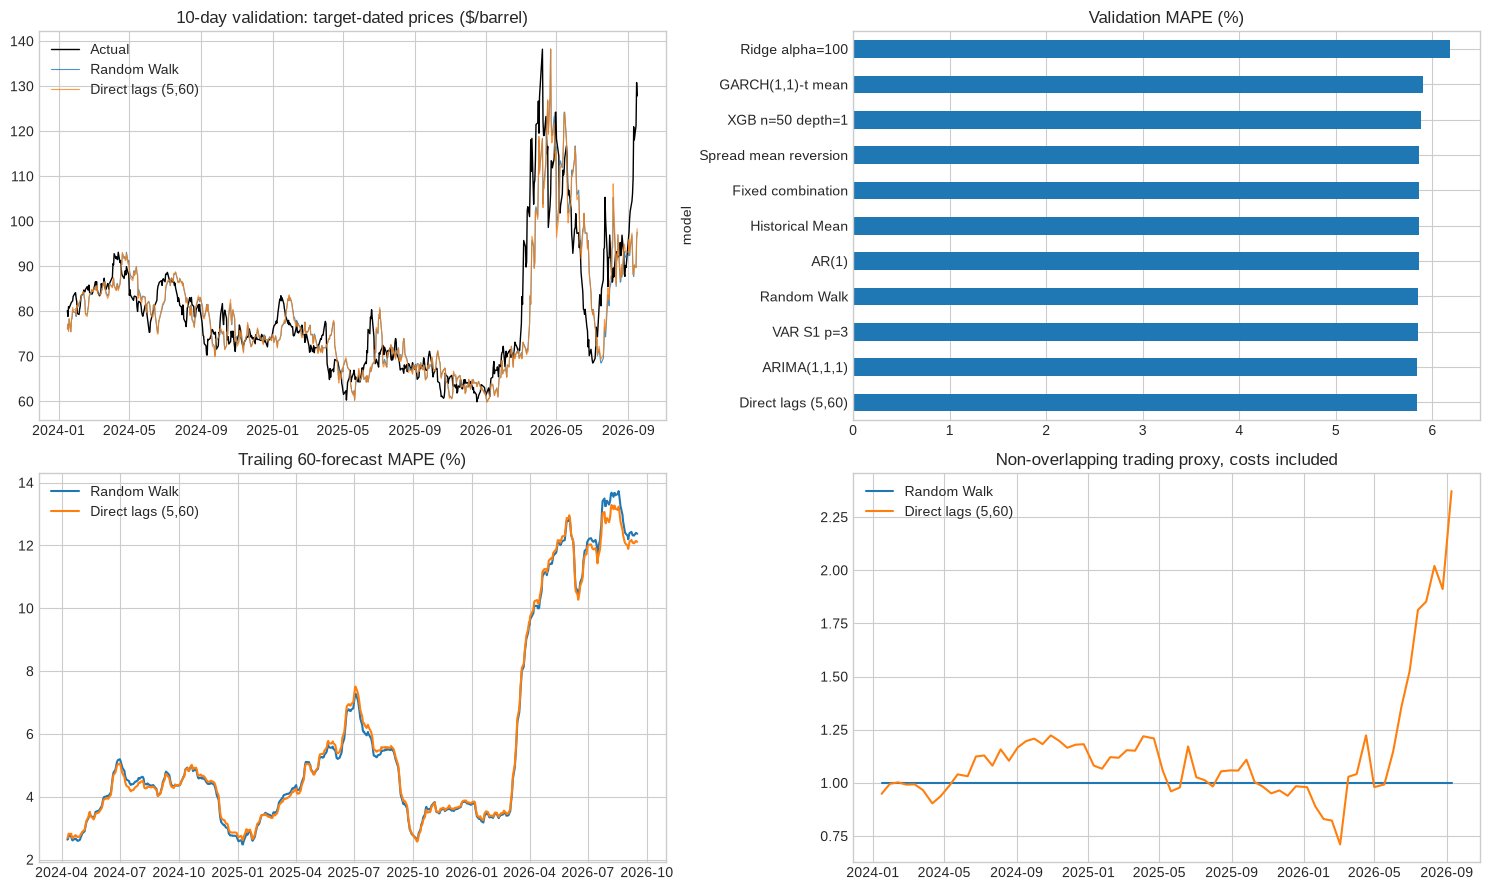

In [11]:
volatility = realised_volatility(df, window=20)
VOL_THRESHOLD = volatility.loc[volatility.index < VAL_START].median()
robust_rows = []
for name in SHORTLIST:
    res = validation_results[name]
    high = volatility.reindex(pd.DatetimeIndex(res.origin_date)).to_numpy() >= VOL_THRESHOLD
    groups = {'high volatility': high, 'low volatility': ~high}
    for year in sorted(res.target_date.dt.year.unique()):
        groups[str(year)] = res.target_date.dt.year.to_numpy() == year
    for group, mask in groups.items():
        if mask.sum():
            robust_rows.append({'model': name, 'group': group, 'n': int(mask.sum()),
                                **accuracy_metrics(res.loc[mask])})
robustness = pd.DataFrame(robust_rows)
print(f'Fixed pre-validation high-volatility threshold: {VOL_THRESHOLD:.2%} daily')
display(robustness.pivot(index='model', columns='group', values='MAPE').round(4))

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
selected = validation_results[WINNER]
axes[0, 0].plot(selected.target_date, selected.actual, label='Actual', color='black', lw=1)
for name in list(dict.fromkeys(['Random Walk', WINNER])):
    r = validation_results[name]
    axes[0, 0].plot(r.target_date, r.forecast, label=name, alpha=0.8, lw=0.8)
axes[0, 0].set_title('10-day validation: target-dated prices ($/barrel)'); axes[0, 0].legend()
val_table.loc[SHORTLIST, 'MAPE'].sort_values().plot.barh(ax=axes[0, 1], title='Validation MAPE (%)')
for name in list(dict.fromkeys(['Random Walk', WINNER])):
    r = validation_results[name]
    ape = (r.actual-r.forecast).abs()/r.actual*100
    axes[1, 0].plot(r.target_date, ape.rolling(60).mean(), label=name)
    _, curve = economic_metrics(r)
    axes[1, 1].plot(curve.target_date, curve.equity, label=name)
axes[1, 0].set_title('Trailing 60-forecast MAPE (%)'); axes[1, 0].legend()
axes[1, 1].set_title('Non-overlapping trading proxy, costs included'); axes[1, 1].legend()
plt.tight_layout(); plt.show()

## 9. Prediction Intervals

GARCH and constant-volatility intervals are evaluated around the same point forecasts. Zero-mean GARCH(1,1) with Student-t errors is fitted using returns available by the estimation date. Frozen-parameter volatility states are subsequently updated using observed returns only.

GARCH intervals use Monte Carlo Student-t innovations with variance updated along each simulated path. Equal-tailed **95% prediction bounds** are constructed in log-return space and converted to prices. The benchmark uses constant fitting-window variance and Normal cumulative innovations. Simulation uses a fixed random seed.

Interval performance is measured by coverage, mean width and the **Winkler score**, which penalises both wide intervals and missed observations. Lower scores are preferable. These approximate conditional intervals omit parameter and model uncertainty. Overlapping forecast outcomes invalidate a simple independent-binomial coverage test.

In [12]:
INTERVAL_LEVEL, N_SIM = 0.95, 4000

def garch_noise_paths(frame, origin_idx, fit_idx, horizon=H, n_sim=N_SIM, mean='Zero'):
    fit = garch_fit(frame, origin_idx, fit_idx, mean=mean)
    nu = float(fit.params['nu'])
    omega, alpha, beta = [float(fit.params[k]) for k in ['omega', 'alpha[1]', 'beta[1]']]
    eps_last = float(np.asarray(fit.resid)[-1])
    var_last = float(np.asarray(fit.conditional_volatility)[-1])**2
    rng = np.random.default_rng(SEED + origin_idx)
    variance = np.full(n_sim, omega + alpha*eps_last**2 + beta*var_last)
    total = np.zeros(n_sim)
    for _ in range(horizon):
        shock = np.sqrt(variance)*rng.standard_t(nu, size=n_sim)*np.sqrt((nu-2)/nu)
        total += shock/100
        variance = omega + alpha*shock**2 + beta*variance
    return total

def interval_row(frame, origin_idx, fit_idx, point, method='GARCH'):
    p0 = float(frame.brent_spot.iloc[origin_idx])
    center = np.log(point/p0)
    tail = (1-INTERVAL_LEVEL)/2
    if method == 'GARCH':
        paths = garch_noise_paths(frame, origin_idx, fit_idx)
        lo, hi = np.quantile(paths, [tail, 1-tail])
    elif method == 'Constant vol':
        sd = frame.log_return.iloc[fit_idx-LOOKBACK+1:fit_idx+1].std(ddof=1)*np.sqrt(H)
        lo, hi = stats.norm.ppf([tail, 1-tail])*sd
    else:
        raise ValueError(method)
    return p0*np.exp(center+lo), p0*np.exp(center+hi)

def add_intervals(res, method='GARCH', freeze=None):
    out = res.copy()
    lower, upper = [], []
    for row in res.itertuples(index=False):
        i = df.index.get_loc(row.origin_date)
        f = i if freeze is None else min(i, df.index.searchsorted(freeze, side='right')-1)
        lo, hi = interval_row(df, i, f, row.forecast, method)
        lower.append(lo); upper.append(hi)
    out['lower'], out['upper'] = lower, upper
    assert (out.lower > 0).all() and (out.upper >= out.lower).all()
    return out

def interval_metrics(res):
    alpha = 1-INTERVAL_LEVEL
    width = res.upper-res.lower
    score = width + 2/alpha*(res.lower-res.actual).clip(lower=0) + 2/alpha*(res.actual-res.upper).clip(lower=0)
    return {'n': len(res), 'nominal_coverage': INTERVAL_LEVEL,
            'coverage': res.actual.between(res.lower, res.upper).mean(),
            'mean_width_USD': width.mean(), 'Winkler_score': score.mean()}

val_intervals = {}
for method in ['GARCH', 'Constant vol']:
    # Fit interval noise once per date, then recenter for the two point models.
    rw_band = add_intervals(validation_results['Random Walk'], method)
    for name in list(dict.fromkeys(['Random Walk', WINNER])):
        band = rw_band.copy()
        ratio = validation_results[name].forecast.to_numpy()/rw_band.forecast.to_numpy()
        band['forecast'] = validation_results[name].forecast.to_numpy()
        band['lower'] *= ratio; band['upper'] *= ratio
        val_intervals[f'{name} | {method}'] = band
    print('Completed validation intervals:', method, flush=True)
interval_table = pd.DataFrame({n: interval_metrics(r) for n, r in val_intervals.items()}).T
display(interval_table.round(4))

Completed validation intervals: GARCH


Completed validation intervals: Constant vol


,n,nominal_coverage,coverage,mean_width_USD,Winkler_score
Random Walk | GARCH,676.0,0.95,0.9216,24.7979,41.9146
"Direct lags (5,60) | GARCH",676.0,0.95,0.9246,24.7727,41.4188
Random Walk | Constant vol,676.0,0.95,0.9453,28.9899,43.4775
"Direct lags (5,60) | Constant vol",676.0,0.95,0.9438,28.9696,42.9121


## 10. October Holdout Evaluation

The prespecified shortlist is evaluated on **17 targets from 1–23 October 2026**. Estimation is capped at the earlier of the origin and **30 September**. October observations may update forecast inputs and model states, but are excluded from parameter estimation.

The validation-selected model is retained regardless of the October ranking. The short holdout contains only about one or two non-overlapping 10-day holding periods, limiting inference about significance and annualised trading performance.

October targets available: 17 ; latest: 2026-10-23
Locked validation winner remains: Direct lags (5,60)


,MAE,RMSE,MAPE,MAPE_vs_RW_%,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,sharpe_ratio,n_holding_periods
model,,,,,,,,,,,,,
Random Walk,9.7741,10.4117,7.8221,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0
Historical Mean,9.7572,10.3671,7.8138,0.1068,0.5882,0.5882,1.0,0.7407,0.0000,0.0000,0.0000,NaN,2.0
AR(1),9.7370,10.3277,7.7976,0.3139,0.6471,0.6250,1.0,0.7692,1.0000,0.1429,0.2500,NaN,2.0
"ARIMA(1,1,1)",9.6278,10.1955,7.7093,1.4420,0.7059,0.6667,1.0,0.8000,1.0000,0.2857,0.4444,NaN,2.0
"Direct lags (5,60)",10.4913,11.4211,8.3572,-6.8403,0.4118,0.0000,0.0,0.0000,0.4118,1.0000,0.5833,NaN,2.0
VAR S1 p=3,9.6808,10.3045,7.7604,0.7886,0.5882,0.6154,0.8,0.6957,0.5000,0.2857,0.3636,NaN,2.0
Spread mean reversion,9.7352,10.3931,7.7877,0.4394,0.5294,1.0000,0.2,0.3333,0.4667,1.0000,0.6364,NaN,2.0
Ridge alpha=100,9.5467,10.9796,7.8076,0.1855,0.5882,0.5882,1.0,0.7407,0.0000,0.0000,0.0000,NaN,2.0
XGB n=50 depth=1,9.7715,10.4020,7.8213,0.0106,0.5882,0.5882,1.0,0.7407,0.0000,0.0000,0.0000,NaN,2.0


/tmp/ipykernel_590/3212170660.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(october_results[WINNER].round(4))


,origin_date,target_date,origin_price,forecast,actual
0,2026-09-17,2026-10-01,121.18,119.3058,114.82
1,2026-09-18,2026-10-02,119.66,118.0595,135.51
2,2026-09-21,2026-10-05,116.15,114.0535,125.51
3,2026-09-22,2026-10-06,114.89,112.2306,125.44
4,2026-09-23,2026-10-07,117.45,114.9520,126.00
5,2026-09-24,2026-10-08,120.92,118.8718,130.18
6,2026-09-25,2026-10-09,116.01,113.9224,130.03
7,2026-09-28,2026-10-12,119.97,118.2268,129.95
8,2026-09-29,2026-10-13,113.96,112.2011,125.78
9,2026-09-30,2026-10-14,115.91,114.1229,126.55


October-only DM: Too few overlapping forecasts for a reliable DM interpretation; p-value suppressed.


,n,nominal_coverage,coverage,mean_width_USD,Winkler_score
GARCH,17.0,0.95,1.0,64.3079,64.3079
Constant vol,17.0,0.95,1.0,46.7460,46.7460


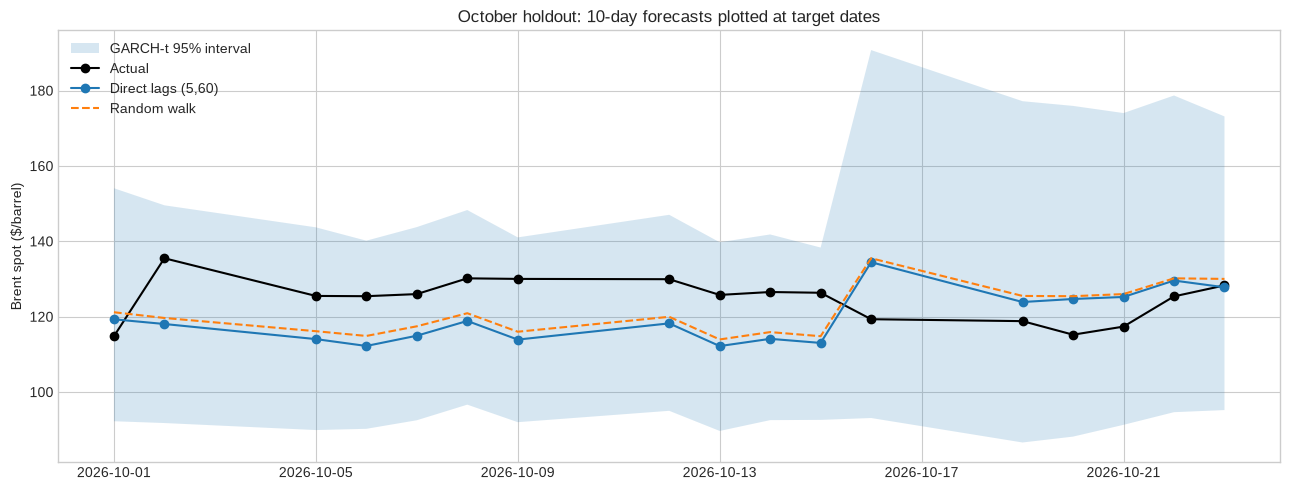

In [13]:
october_results = {}
for name in SHORTLIST:
    october_results[name] = run_target_window(MODELS[name], name, TEST_START, TEST_END,
                                               fit_cutoff=FIT_CUTOFF)
N_TEST = assert_common(october_results)
assert WINNER == locked_winner
for res in october_results.values():
    assert res.target_date.between(TEST_START, TEST_END).all()
    assert res.origin_date.min() == FIRST_TEST_ORIGIN

oct_table = comparison_table(october_results)
for name, res in october_results.items():
    econ, _ = economic_metrics(res)
    for field in ['annualized_return', 'sharpe_ratio', 'max_drawdown']:
        oct_table.loc[name, field] = econ[field]
    oct_table.loc[name, 'n_holding_periods'] = econ['n_holding_periods']
    oct_table.loc[name, 'num_trades'] = econ['turnover']
print('October targets available:', N_TEST, '; latest:', october_results[WINNER].target_date.max().date())
print('Locked validation winner remains:', WINNER)
# Keep shortlist order rather than displaying an October-derived winner.
display(oct_table[['MAE', 'RMSE', 'MAPE', 'MAPE_vs_RW_%', 'directional_accuracy',
                   'precision_up', 'recall_up', 'f1_up', 'precision_down', 'recall_down', 'f1_down',
                   'sharpe_ratio', 'n_holding_periods']].round(4))
display(october_results[WINNER].round(4))
print('October-only DM:', dm_test(october_results[WINNER], october_results['Random Walk'])['note'])

oct_intervals = {method: add_intervals(october_results[WINNER], method, freeze=FIT_CUTOFF)
                 for method in ['GARCH', 'Constant vol']}
display(pd.DataFrame({n: interval_metrics(r) for n, r in oct_intervals.items()}).T.round(4))
band = oct_intervals['GARCH']
fig, ax = plt.subplots(figsize=(13, 5))
ax.fill_between(band.target_date, band.lower, band.upper, alpha=0.18, label='GARCH-t 95% interval')
ax.plot(band.target_date, band.actual, marker='o', color='black', label='Actual')
ax.plot(band.target_date, band.forecast, marker='o', label=WINNER)
ax.plot(band.target_date, october_results['Random Walk'].forecast, linestyle='--', label='Random walk')
ax.set(title='October holdout: 10-day forecasts plotted at target dates', ylabel='Brent spot ($/barrel)')
ax.legend(); plt.tight_layout(); plt.show()

## 11. Direct-Regression Coefficient Diagnostics

A prespecified direct regression is fitted through the last pre-validation observation. The dependent variable is the future 10-day log return. Predictors are the latest 1-day return and the preceding, non-overlapping 19-day return. Every training label is observed by the fitting date.

Newey–West/HAC standard errors with lag 10 address overlapping labels and heteroskedasticity. These coefficient statistics describe the regression; they do not establish causality or out-of-sample superiority. The selected model's final coefficients are reported in the conclusion.

In [14]:
def explanatory_ols(fit_idx):
    lp = np.log(df.brent_spot.to_numpy())
    start = fit_idx-LOOKBACK+1
    t = np.arange(start+20, fit_idx-H+1)
    X = pd.DataFrame({'latest_1d': lp[t]-lp[t-1], 'preceding_19d': lp[t-1]-lp[t-20]})
    y = lp[t+H]-lp[t]
    assert (t+H).max() <= fit_idx
    fit = sm.OLS(y, sm.add_constant(X)).fit(cov_type='HAC', cov_kwds={'maxlags': H})
    ci = fit.conf_int()
    table = pd.DataFrame({'coefficient': fit.params, 'HAC_se': fit.bse, 't': fit.tvalues,
                          'p_value': fit.pvalues, 'CI_low': ci[0], 'CI_high': ci[1]})
    return fit, table

explain_idx = np.flatnonzero(df.index < VAL_START)[-1]
ols_fit, ols_table = explanatory_ols(explain_idx)
print('Training-only explanatory fit through', df.index[explain_idx].date(), '; observations:', int(ols_fit.nobs))
display(ols_table.round(5))

Training-only explanatory fit through 2023-12-29 ; observations: 2970


,coefficient,HAC_se,t,p_value,CI_low,CI_high
const,-0.00118,0.00421,-0.28004,0.77944,-0.00943,0.00708
latest_1d,-0.02637,0.22938,-0.11494,0.90849,-0.47593,0.42320
preceding_19d,0.09310,0.05357,1.73792,0.08223,-0.01189,0.19810


## 12. Final 10-Day Forecast

The validation-selected specification is refitted using information through the **30 September 2026** origin and predicts the price 10 observed Brent days ahead. The corresponding target is **14 October 2026**. Its subsequently observed price is used only for evaluation.

Predicted log returns are converted to price levels as \(P_t\exp(\widehat y_{t,10})\). This is a plug-in central, median-style forecast rather than an unbiased conditional mean dollar price. MAPE remains the selection criterion even when other metrics favour another model.

Historical targets use the observed Brent calendar. Future targets without an observed calendar receive an explicitly approximate weekday date. Prediction intervals represent conditional uncertainty rather than guaranteed bounds.

In [15]:
def final_forecast(origin_date, refit_latest=False):
    i = df.index.searchsorted(pd.Timestamp(origin_date), side='right')-1
    if i < LOOKBACK or df.index[i] != pd.Timestamp(origin_date):
        raise ValueError(f'Origin {origin_date} is not an available modelling observation; choose an observed date explicitly.')
    f = i if refit_latest else min(i, df.index.searchsorted(FIT_CUTOFF, side='right')-1)
    price = checked_model(MODELS[WINNER], WINNER)(df, i, H, f)
    lower, upper = interval_row(df, i, f, price, 'GARCH')
    if i+H < len(df):
        target, calendar_note = df.index[i+H], 'exact: 10 observed Brent days'
        actual = float(df.brent_spot.iloc[i+H])
    else:
        target = pd.bdate_range(df.index[i], periods=H+1)[-1]
        calendar_note, actual = 'approximate weekday date; actual Brent calendar not yet observed', np.nan
    row = {'model': WINNER, 'origin_date': df.index[i], 'fit_through': df.index[f],
           'target_date': target, 'calendar': calendar_note,
           'origin_price': float(df.brent_spot.iloc[i]), 'forecast': price,
           'forecast_log_return': float(np.log(price/df.brent_spot.iloc[i])),
           'lower_95': lower, 'upper_95': upper, 'actual_if_available': actual}
    return pd.DataFrame([row])

final = final_forecast(FINAL_ORIGIN)
display(final.T)
row = final.iloc[0]
print(f'Locked model: {WINNER}')
print(f'Origin {row.origin_date.date()}, Brent spot ${row.origin_price:.2f}/barrel')
print(f'10-day forecast for {row.target_date.date()}: ${row.forecast:.2f}/barrel')
print(f'Approximate GARCH-t 95% interval: ${row.lower_95:.2f}–${row.upper_95:.2f}/barrel')

,0
model,"Direct lags (5,60)"
origin_date,2026-09-30 00:00:00
fit_through,2026-09-30 00:00:00
target_date,2026-10-14 00:00:00
calendar,exact: 10 observed Brent days
origin_price,115.91
forecast,114.122894
forecast_log_return,-0.015538
lower_95,92.546884
upper_95,141.828452


Locked model: Direct lags (5,60)
Origin 2026-09-30, Brent spot $115.91/barrel
10-day forecast for 2026-10-14: $114.12/barrel
Approximate GARCH-t 95% interval: $92.55–$141.83/barrel


### Updating the Forecast

The update procedure refits the same selected specification using the latest available observations. It is separate from the fixed September-origin evaluation and does not reselect the model using October performance.

The forecast origin is the latest published observation date, which may lag the current date. Real-time implementation would also require publication-time controls, a suitable trading calendar and scheduled data ingestion.

In [16]:
RUN_LATEST_UPDATE = False
latest = pd.DataFrame()
if RUN_LATEST_UPDATE:
    latest = final_forecast(df.index[-1], refit_latest=True)
    print('Daily update; this is separate from the fixed September assignment forecast.')
    display(latest.T)

## 13. Results Summary and Reproducibility

The analysis records the input snapshot and hash, model-selection specification, candidate forecasts, evaluation tables, significance tests, interval results and final forecast. These outputs provide an audit trail for the comparison.

The following summary reports the selected model's validation and holdout performance together with the principal limitations.

In [17]:
val_table.to_csv(OUT/'validation_model_comparison.csv')
oct_table.to_csv(OUT/'october_model_comparison.csv')
robustness.to_csv(OUT/'robustness.csv', index=False)
economic_sensitivity.to_csv(OUT/'sharpe_start_offset_sensitivity.csv')
interval_table.to_csv(OUT/'validation_interval_comparison.csv')
final.to_csv(OUT/'final_10day_forecast.csv', index=False)
if not latest.empty:
    latest.to_csv(OUT/'latest_10day_forecast.csv', index=False)
for key, table in dm_tables.items():
    table.to_csv(OUT/f'dm_{key}.csv')
for stage, results in [('validation', validation_results), ('october', october_results)]:
    pd.concat([r.assign(model=n) for n, r in results.items()], ignore_index=True).to_csv(
        OUT/f'{stage}_all_forecasts.csv', index=False)
for stage, results in [('validation', val_intervals), ('october', oct_intervals)]:
    pd.concat([r.assign(interval_model=n) for n, r in results.items()], ignore_index=True).to_csv(
        OUT/f'{stage}_interval_forecasts.csv', index=False)
df.to_csv(OUT/'model_inputs.csv', index_label='date')
versions = {p: importlib.metadata.version(p) for p in ['numpy', 'pandas', 'scipy', 'statsmodels',
            'scikit-learn', 'xgboost', 'arch', 'matplotlib', 'yfinance', 'pandas-datareader']}
manifest = {'data_source': input_source, 'input_csv_sha256': DATA_HASH,
            'observation_start': str(raw.index[0].date()), 'observation_end': str(raw.index[-1].date()),
            'run_utc': pd.Timestamp.now(tz='UTC').isoformat(), 'python': sys.version,
            'versions': versions, 'selection': selection_record,
            'shared_source_sha256': {f: hashlib.sha256((ROOT/'src'/f).read_bytes()).hexdigest()
                                     for f in ['data.py', 'models.py', 'features.py', 'backtest.py', 'metrics.py']}}
(OUT/'run_manifest.json').write_text(json.dumps(manifest, indent=2))

winner_gain = float(val_table.loc[WINNER, 'MAPE_vs_RW_%'])
significance = 'Random walk itself was selected; no superiority test applies.'
if WINNER != 'Random Walk':
    p = float(dm_tables[f'ape_lag{H-1}'].loc[WINNER, 'p_Holm'])
    significance = (f'Validation DM (APE, HAC lag {H-1}) Holm-adjusted p={p:.4f}. '
                    'This is a selection-period diagnostic, not independent confirmation.')
summary = f"""### Summary of Findings
- **Target:** Brent spot, {H} observed trading days ahead; daily rolling {LOOKBACK}-observation fits.
- **Model selection:** {WINNER}, chosen by validation MAPE through {SELECTION_END.date()}, before the first October-test origin.
- **Validation:** {N_VAL} forecasts; MAPE {val_table.loc[WINNER, 'MAPE']:.3f}%; relative improvement versus RW {winner_gain:+.2f}%.
- **Evidence:** {significance}
- **Holdout:** {N_TEST} target observations, {october_results[WINNER].target_date.min().date()}–{october_results[WINNER].target_date.max().date()}; MAPE {oct_table.loc[WINNER, 'MAPE']:.3f}%. No reselection.
- **Final forecast:** ${row.forecast:.2f}/barrel for {row.target_date.date()}, from the {row.origin_date.date()} origin; GARCH-t interval ${row.lower_95:.2f}–${row.upper_95:.2f}.
- **Limitations:** overlapping forecast errors; short October holdout; revised observation-dated data rather than historical release vintages; approximate interval/model uncertainty; spot trading proxy is not an investable futures backtest.
"""
display(Markdown(summary))
(OUT/'presentation_summary.md').write_text(summary)
print('Exported to:', OUT)
print('Evaluation tables and forecast CSVs saved.')

### Summary of Findings
- **Target:** Brent spot, 10 observed trading days ahead; daily rolling 3000-observation fits.
- **Model selection:** Direct lags (5,60), chosen by validation MAPE through 2026-09-16, before the first October-test origin.
- **Validation:** 676 forecasts; MAPE 5.841%; relative improvement versus RW +0.15%.
- **Evidence:** Validation DM (APE, HAC lag 9) Holm-adjusted p=1.0000. This is a selection-period diagnostic, not independent confirmation.
- **Holdout:** 17 target observations, 2026-10-01–2026-10-23; MAPE 8.357%. No reselection.
- **Final forecast:** $114.12/barrel for 2026-10-14, from the 2026-09-30 origin; GARCH-t interval $92.55–$141.83.
- **Limitations:** overlapping forecast errors; short October holdout; revised observation-dated data rather than historical release vintages; approximate interval/model uncertainty; spot trading proxy is not an investable futures backtest.


Exported to: /workspace/Sample-Taxed/data/h10_outputs
Evaluation tables and forecast CSVs saved.


## References

- FRED/EIA: [Europe Brent Spot Price FOB, DCOILBRENTEU](https://fred.stlouisfed.org/series/DCOILBRENTEU); WTI `DCOILWTICO`; broad USD index `DTWEXBGS`; VIX `VIXCLS`; OVX `OVXCLS`.
- Yahoo Finance: S&P 500 index, `^GSPC`.
- Diebold, F. X. and Mariano, R. S. (1995). Comparing Predictive Accuracy. *Journal of Business & Economic Statistics*, 13(3), 253–263.
- Harvey, D., Leybourne, S. and Newbold, P. (1997). Testing the Equality of Prediction Mean Squared Errors. *International Journal of Forecasting*, 13(2), 281–291.
- Newey, W. K. and West, K. D. (1987). A Simple, Positive Semi-Definite, Heteroskedasticity and Autocorrelation Consistent Covariance Matrix. *Econometrica*, 55(3), 703–708.
- Bollerslev, T. (1986). Generalized Autoregressive Conditional Heteroskedasticity. *Journal of Econometrics*, 31(3), 307–327.
- Holm, S. (1979). A Simple Sequentially Rejective Multiple Test Procedure. *Scandinavian Journal of Statistics*, 6(2), 65–70.

## 14. Conclusions

**Direct lags (5,60)** achieved the lowest validation MAPE: **5.8408%**, compared with **5.8493%** for random walk over 676 common forecasts. Its relative improvement was only **0.145%**. The MAPE-loss Diebold–Mariano test gave an unadjusted p-value of **0.8228** and a Holm-adjusted p-value of **1.0000**, providing no statistically persuasive evidence of superiority.

On the 17 October holdout targets, the selected model's MAPE increased to **8.3572%**, compared with **7.8221%** for random walk. ARIMA(1,1,1) recorded **7.7093%**, but the validation-selected specification was retained to preserve the separation between selection and testing. The small validation advantage did not persist in October.

From a **30 September** spot price of **$115.91/barrel**, the selected model forecast **$114.12/barrel for 14 October**, with an approximate GARCH-t 95% interval of **$92.55–$141.83**. The subsequently observed price was **$126.55**.

Validation coverage for the selected model's GARCH interval was **92.46%**, below the nominal 95%. The constant-volatility benchmark achieved **94.38%** coverage with wider intervals. GARCH had a lower mean Winkler score but exhibited undercoverage.

### Selected Model

The model predicts the next 10-day log return from the latest 5-day return and the preceding 55-day return, plus an intercept:

\[
\widehat y_{t,10}=0.002777
+0.035404\log(P_t/P_{t-5})
-0.036247\log(P_{t-5}/P_{t-60}).
\]

The coefficients below are from the 30 September fit, based on **2,930 overlapping training labels**.

| Term | Coefficient | HAC standard error | p-value |
|---|---:|---:|---:|
| Intercept | 0.002777 | 0.004896 | 0.5705 |
| Latest 5-day return | 0.035404 | 0.151673 | 0.8154 |
| Preceding 55-day return | −0.036247 | 0.048367 | 0.4536 |

These post-selection coefficient statistics are descriptive rather than independent evidence of forecasting skill. The displayed equation uses rounded coefficients; the price forecast uses the full-precision estimates.

Overall, 10-day Brent spot forecasting was difficult in this sample. The direct regression narrowly led validation without significant improvement over random walk, and performed worse in the short holdout. Overlapping outcomes, revised observation-dated data, publication lags and incomplete model uncertainty remain material limitations.

*Results correspond to the archived data snapshot with observations through 27 October 2026.*